<a href="https://colab.research.google.com/github/Gloou-ui/NM/blob/main/%D0%9B%D0%A0_6_%D0%9B%D0%B8%D1%82%D0%B2%D0%B8%D0%BD_%D0%A4%D0%86%D0%A23_10_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
%pip -q install kagglehub imbalanced-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


*Спосіб 1 не використовується. У цій роботі обрано спосіб 2 — завантаження з Kaggle через kagglehub.*


**Спосіб 2.** Завантаження датасету з Kaggle через `kagglehub` (цей спосіб використовується в роботі).

In [2]:
import kagglehub

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
print("Шлях до завантаженого датасету:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Шлях до завантаженого датасету: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))

required_columns = {
    "gender", "smoking_history", "age", "bmi",
    "HbA1c_level", "blood_glucose_level", "diabetes"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(
        "Завантажено не той датасет. "
        f"Не знайдено колонки: {sorted(missing_columns)}. "
        "Потрібен diabetes_prediction_dataset.csv з Kaggle."
    )

display(df.head())
print("Розмір датасету:", df.shape)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Розмір датасету: (100000, 9)


Вивести інформацію про датасет

In [4]:
df.info()
print("\nТипи даних:")
print(df.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Типи даних:
int64      4
float64    3
object     2
Name: count, dtype: int64


Провести дослідження категоріальних ознак

In [5]:
display(df["gender"].value_counts(dropna=False))

,count
gender,
Female,58552
Male,41430
Other,18


In [6]:
display(df["smoking_history"].value_counts(dropna=False))

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [7]:
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Вивести типи даних

In [8]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [9]:
display(df["diabetes"].value_counts(dropna=False))
display((df["diabetes"].value_counts(normalize=True, dropna=False) * 100).round(2).rename("Частка, %"))

,count
diabetes,
0,91500
1,8500


,"Частка, %"
diabetes,
0,91.5
1,8.5


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [10]:
display(df.isnull().sum())

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [11]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 3854


Видалити дублікати

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
display(df.head())
print("Розмір після видалення дублікатів:", df.shape)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Розмір після видалення дублікатів: (96146, 9)


Ще раз перевірити баланс цільової змінної

In [14]:
display(df["diabetes"].value_counts())
display((df["diabetes"].value_counts(normalize=True) * 100).round(2).rename("Частка, %"))

,count
diabetes,
0,87664
1,8482


,"Частка, %"
diabetes,
0,91.18
1,8.82


Побудувати гістограму для цільової змінної


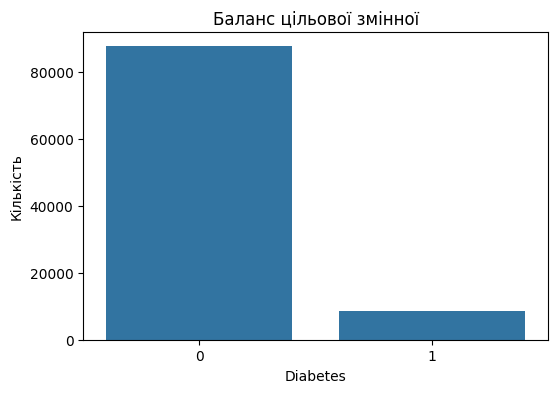

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(x="diabetes", data=df, color="tab:blue")
plt.title("Баланс цільової змінної")
plt.xlabel("Diabetes")
plt.ylabel("Кількість")
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [16]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [17]:
X = df.drop(columns=["diabetes"]).copy()
y = df["diabetes"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("Розподіл класів у train:")
display(y_train.value_counts().sort_index())
print("Розподіл класів у test (лише контроль, без балансування):")
display(y_test.value_counts().sort_index())

X_train: (76916, 8) X_test: (19230, 8)
Розподіл класів у train:


,count
diabetes,
0,70130
1,6786


Розподіл класів у test (лише контроль, без балансування):


,count
diabetes,
0,17534
1,1696


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [18]:
X_train = pd.get_dummies(X_train, columns=["gender", "smoking_history"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["gender", "smoking_history"], dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train = X_train.apply(pd.to_numeric, errors="coerce")
X_test = X_test.apply(pd.to_numeric, errors="coerce")
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())

print("Кількість ознак у train:", X_train.shape[1])
print("Кількість ознак у test:", X_test.shape[1])
print("Стовпці однакові:", X_train.columns.equals(X_test.columns))

Кількість ознак у train: 15
Кількість ознак у test: 15
Стовпці однакові: True


In [19]:
display(X_train.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [20]:
corr_target = X_train.copy()
corr_target["diabetes"] = y_train
target_corr = corr_target.corr(numeric_only=True)["diabetes"].drop("diabetes").sort_values(key=lambda s: s.abs(), ascending=False)
display(target_corr.to_frame("Кореляція з diabetes"))

,Кореляція з diabetes
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_No Info,-0.113053
smoking_history_former,0.096162
gender_Male,0.040650
gender_Female,-0.040533


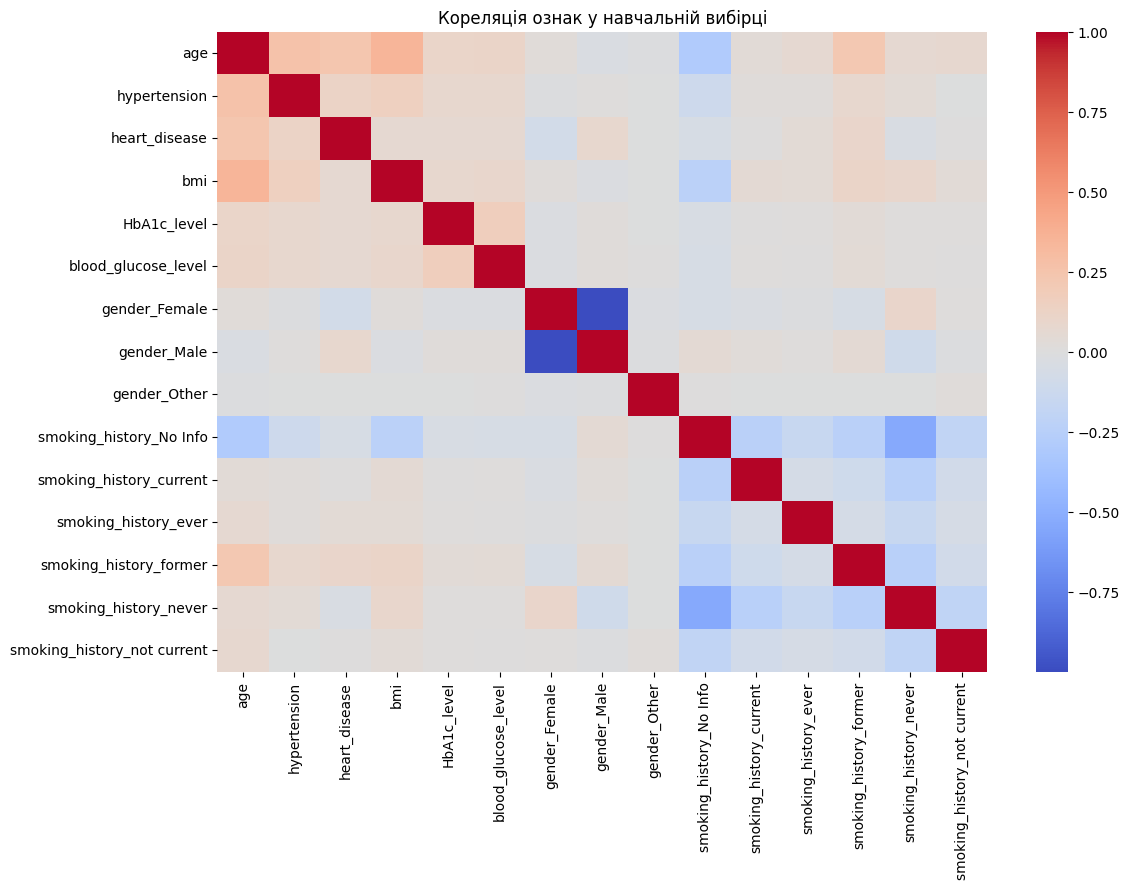

In [21]:
feature_corr = X_train.corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(feature_corr, cmap="coolwarm", center=0, annot=False)
plt.title("Кореляція ознак у навчальній вибірці")
plt.tight_layout()
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

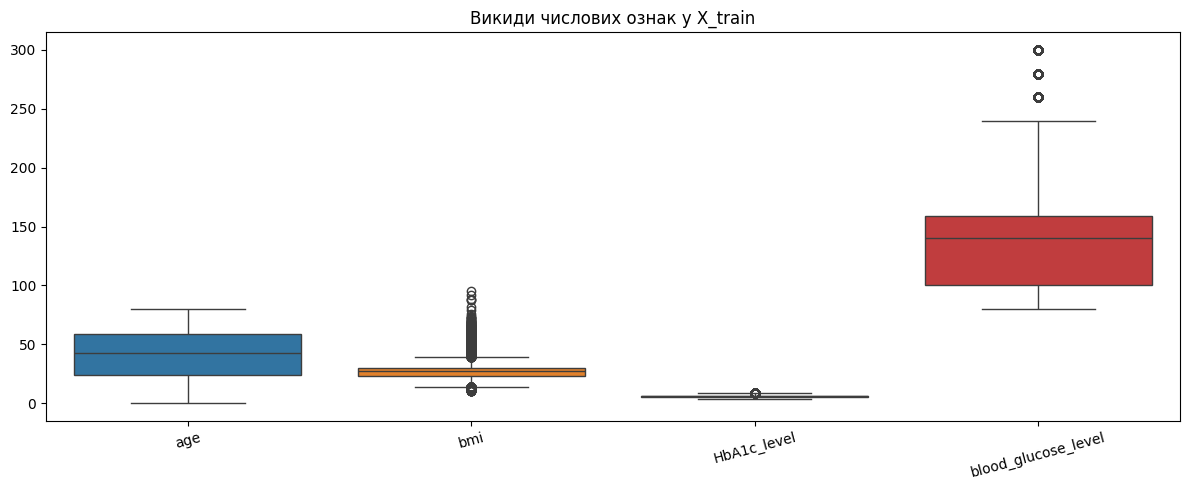

,Q1,Q3,IQR,Нижня межа,Верхня межа,Кількість значень за межами
Ознака,,,,,,
age,24.00,59.00,35.00,-28.5,111.50,0
bmi,23.39,29.85,6.46,13.7,39.54,4244
HbA1c_level,4.80,6.20,1.40,2.7,8.30,1041
blood_glucose_level,100.00,159.00,59.00,11.5,247.50,1598


In [22]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

plt.figure(figsize=(12, 5))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Викиди числових ознак у X_train")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Межі IQR та кількість значень за межами цих меж — тільки за X_train.
iqr_rows = []
for col in continuous_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    iqr_rows.append({
        "Ознака": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Нижня межа": lower,
        "Верхня межа": upper,
        "Кількість значень за межами": int(count)
    })

iqr_summary = pd.DataFrame(iqr_rows).set_index("Ознака")
display(iqr_summary.round(3))

**Висновок:** межі IQR і кількість потенційних викидів розраховано лише за `X_train`. Викиди перевіряємо, але автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими. `X_test` та `y_test` залишаються незмінними.


**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [23]:
skewness = X_train[continuous_cols].skew().sort_values(key=lambda s: s.abs(), ascending=False)
display(skewness.to_frame("Асиметрія"))

,Асиметрія
bmi,1.005016
blood_glucose_level,0.830778
age,-0.061461
HbA1c_level,-0.055651


In [24]:
print("Пропуски у X_train:")
display(X_train.isnull().sum())
print("Пропуски у X_test:")
display(X_test.isnull().sum())

Пропуски у X_train:


,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


Пропуски у X_test:


,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір X_train_scaled:", X_train_scaled.shape)
print("Розмір X_test_scaled:", X_test_scaled.shape)


Розмір X_train_scaled: (76916, 15)
Розмір X_test_scaled: (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [26]:
print("Класи до SMOTE:")
display(y_train.value_counts().sort_index())

smote = SMOTE(random_state=42, k_neighbors=3)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("Класи після SMOTE:")
display(pd.Series(y_train_resampled).value_counts().sort_index())

Класи до SMOTE:


,count
diabetes,
0,70130
1,6786


Класи після SMOTE:


,count
diabetes,
0,70130
1,70130


Оголошуємо моделі

In [27]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RidgeClassifier": RidgeClassifier(),
    "SGDClassifier": SGDClassifier(random_state=42, max_iter=1000, tol=1e-3),
    "SVC": SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


In [29]:
print([name for name in ["models", "X_train_resampled", "y_train_resampled", "X_test_scaled", "y_test"] if name not in globals()])
print(models.keys())

[]
dict_keys(['LogisticRegression', 'RidgeClassifier', 'SGDClassifier', 'SVC'])



LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



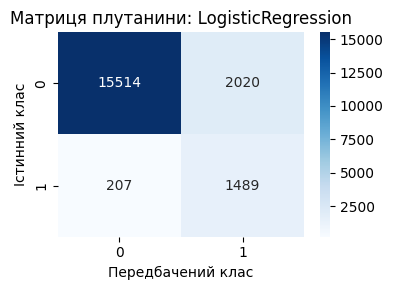


RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



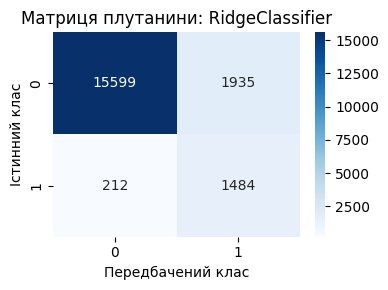


SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.90      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.69      0.88      0.73     19230
weighted avg       0.94      0.86      0.89     19230



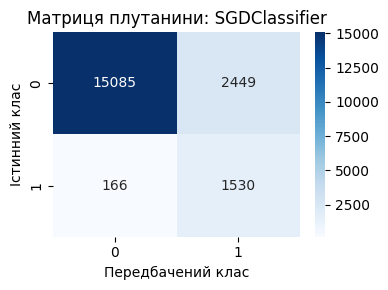


SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



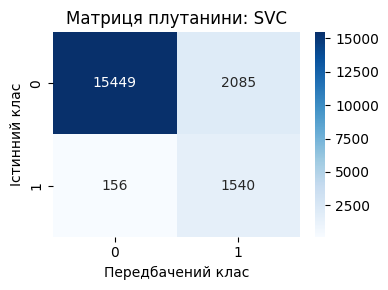

In [28]:
if "models" not in globals():
    models = {
        "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
        "RidgeClassifier": RidgeClassifier(),
        "SGDClassifier": SGDClassifier(random_state=42, max_iter=1000, tol=1e-3),
        "SVC": SVC(random_state=42)
    }

model_results = {}

for name, model in models.items():
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)
    model_results[name] = {
        "model": model,
        "prediction": y_pred,
        "report": classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    }
    print(f"\n{name}")
    print(classification_report(y_test, y_pred, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Матриця плутанини: {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Істинний клас")
    plt.tight_layout()
    plt.show()


Оптимізувати гіперпараметри


In [30]:
param_grids = {
    "LogisticRegression": [
        {"model__C": [0.1, 1.0, 10.0], "model__solver": ["lbfgs"], "model__penalty": ["l2"]}
    ],
    "RidgeClassifier": [
        {"model__alpha": [0.1, 1.0, 10.0]}
    ],
    "SGDClassifier": [
        {"model__loss": ["hinge", "log_loss"], "model__alpha": [0.0001, 0.001], "model__penalty": ["l2"]}
    ],
    "SVC": [
        {"model__C": [0.1, 1.0], "model__kernel": ["linear", "rbf"]}
    ]
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [31]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline


LogisticRegression
Найкращі параметри: {'model__C': 1.0, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Середній F1 на кросвалідації: 0.5813
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



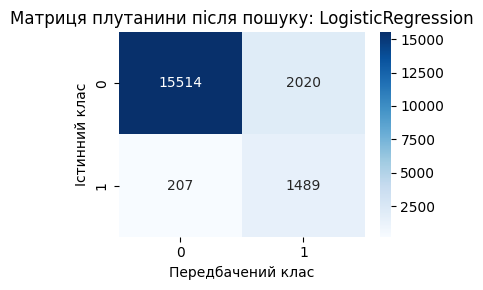


RidgeClassifier
Найкращі параметри: {'model__alpha': 10.0}
Середній F1 на кросвалідації: 0.5919
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



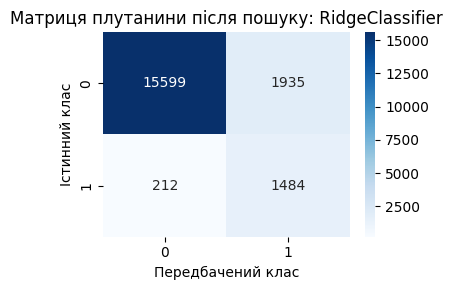


SGDClassifier
Найкращі параметри: {'model__alpha': 0.0001, 'model__loss': 'log_loss', 'model__penalty': 'l2'}
Середній F1 на кросвалідації: 0.5843
              precision    recall  f1-score   support

           0       0.99      0.87      0.93     17534
           1       0.40      0.89      0.55      1696

    accuracy                           0.87     19230
   macro avg       0.69      0.88      0.74     19230
weighted avg       0.94      0.87      0.89     19230



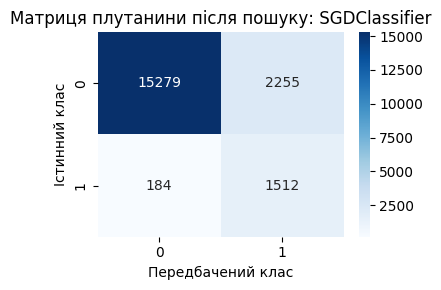


SVC
Найкращі параметри: {'model__C': 0.1, 'model__kernel': 'linear'}
Середній F1 на кросвалідації: 0.6191
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



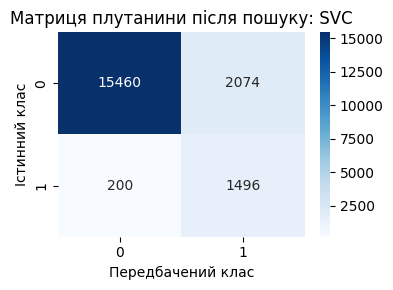

In [32]:

best_models = {}
best_scores = {}

for name, model in models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42, k_neighbors=3)),
        ("model", model)
    ])

    search = HalvingGridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        cv=3,
        scoring="f1",
        min_resources=1000,
        factor=3,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    y_pred = search.best_estimator_.predict(X_test)

    print(f"\n{name}")
    print("Найкращі параметри:", search.best_params_)
    print(f"Середній F1 на кросвалідації: {search.best_score_:.4f}")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Матриця плутанини після пошуку: {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Істинний клас")
    plt.tight_layout()
    plt.show()


Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [33]:

if not best_scores:
    print("Немає результатів кросвалідації. Спочатку виконай комірку № 61.")
else:
    best_name = max(best_scores, key=best_scores.get)
    best_model = best_models[best_name]

    print("Найкраща модель за середнім F1 на кросвалідації:", best_name)
    print(f"Середній F1: {best_scores[best_name]:.4f}")


Найкраща модель за середнім F1 на кросвалідації: SVC
Середній F1: 0.6191


In [34]:
if best_scores:
    best_name = max(best_scores, key=best_scores.get)
    best_model = best_models[best_name]
    print("Найкраща модель за середнім F1 на кросвалідації:", best_name)
    print(f"Середній F1: {best_scores[best_name]:.4f}")
else:
    print("Спочатку виконайте клітинку підбору гіперпараметрів.")


Найкраща модель за середнім F1 на кросвалідації: SVC
Середній F1: 0.6191


Для прогнозування нижче використовується найкраща модель, навчена під час крос-валідаційного пошуку на основному `X_train`. Повторного поділу даних немає.


In [35]:
rng = np.random.default_rng(42)

if "best_model" not in globals() or "best_name" not in globals():
    raise RuntimeError("Спочатку виконайте клітинку підбору гіперпараметрів і вибору найкращої моделі.")

sample_size = min(10, len(X_test))
sample_indices = rng.choice(X_test.index.to_numpy(), size=sample_size, replace=False)
sample_X = X_test.loc[sample_indices]

sample_pred = best_model.predict(sample_X)
sample_pred = np.asarray(sample_pred).reshape(-1).astype(int)

sample_results = pd.DataFrame({
    "Індекс": sample_indices,
    "Істинний клас": y_test.loc[sample_indices].to_numpy().astype(int),
    "Передбачений клас": sample_pred
})

print("Модель:", best_name)
display(sample_results.reset_index(drop=True))


Модель: SVC


,Індекс,Істинний клас,Передбачений клас
0,72555,0,1
1,42651,1,1
2,9181,0,0
3,67901,0,0
4,25253,0,0
5,58082,0,0
6,41116,0,1
7,63015,0,0
8,76480,0,0
9,15158,0,0


In [36]:
print("Доступні результати базових моделей:", list(model_results.keys()))
print("Доступні результати пошуку параметрів:", list(best_models.keys()))


Доступні результати базових моделей: ['LogisticRegression', 'RidgeClassifier', 'SGDClassifier', 'SVC']
Доступні результати пошуку параметрів: ['LogisticRegression', 'RidgeClassifier', 'SGDClassifier', 'SVC']


**Підсумкові висновки (заповніть за отриманими результатами):**

1. Який дисбаланс класів спостерігався? Що показали кореляція, межі IQR та перевірка викидів лише на `train`?
2. Які основні моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яку модель обрано за середнім F1 на крос-валідації?
3. Як результати XGBoost, LightGBM і CatBoost порівнюються з основними моделями на тому самому тестовому наборі?
4. Чому тестову вибірку не балансували та не використовували для аналізу кореляцій і викидів?


**Додаткове завдання.**

XGBoost, LightGBM і CatBoost оцінюються на тому самому `X_test` та `y_test`, що й основні моделі. Повторного `train_test_split` немає. Для узгодженості з основною частиною використовується те саме кодування ознак; SMOTE застосовується лише до навчальної вибірки додаткових моделей.

Для кожної моделі виводяться класифікаційний звіт і матриця плутанини, після чого моделі порівнюються за метриками класу `diabetes = 1`.


**Примітка:** у всьому ноутбуці використовується лише датасет `diabetes_prediction_dataset.csv` та цільова змінна `diabetes`. Дані іншої задачі (наприклад, `churn`) не завантажуються і не перезаписують робочі змінні.



XGBoost
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.70      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



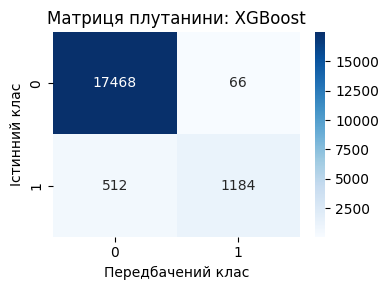


LightGBM
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.94      0.70      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



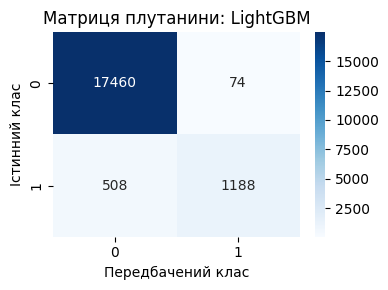


CatBoost
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.70      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



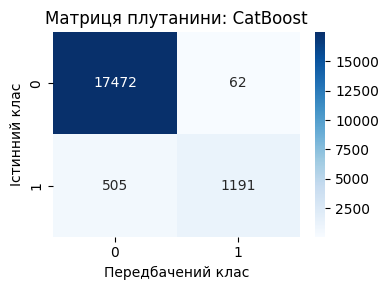

,Модель,Accuracy,Precision для diabetes=1,Recall для diabetes=1,F1 для diabetes=1
2,CatBoost,0.970515,0.950519,0.702241,0.807731
0,XGBoost,0.969943,0.947200,0.698113,0.803802
1,LightGBM,0.969735,0.941363,0.700472,0.803245


Найкраща додаткова модель за F1: CatBoost
F1 для diabetes=1: 0.8077
Recall для diabetes=1: 0.7022


In [37]:
%pip -q install xgboost lightgbm catboost

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix

smote_extra = SMOTE(random_state=42, k_neighbors=3)
X_train_extra, y_train_extra = smote_extra.fit_resample(X_train, y_train)
X_test_extra, y_test_extra = X_test.copy(), y_test.copy()

extra_models = {
    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=150,
        learning_rate=0.1,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=150,
        depth=5,
        learning_rate=0.1,
        verbose=0,
        random_seed=42,
        thread_count=-1
    )
}

extra_results = {}

for name, model in extra_models.items():
    print(f"\n{'=' * 50}\n{name}\n{'=' * 50}")
    model.fit(X_train_extra, y_train_extra)
    pred_extra = np.asarray(model.predict(X_test_extra)).reshape(-1).astype(int)

    report_extra = classification_report(
        y_test_extra, pred_extra, output_dict=True, zero_division=0
    )
    extra_results[name] = {
        "model": model,
        "prediction": pred_extra,
        "accuracy": report_extra["accuracy"],
        "precision": report_extra["1"]["precision"],
        "recall": report_extra["1"]["recall"],
        "f1": report_extra["1"]["f1-score"]
    }

    print(classification_report(y_test_extra, pred_extra, zero_division=0))
    cm_extra = confusion_matrix(y_test_extra, pred_extra, labels=[0, 1])
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm_extra, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Матриця плутанини: {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Істинний клас")
    plt.tight_layout()
    plt.show()

extra_comparison = pd.DataFrame([
    {
        "Модель": name,
        "Accuracy": values["accuracy"],
        "Precision для diabetes=1": values["precision"],
        "Recall для diabetes=1": values["recall"],
        "F1 для diabetes=1": values["f1"]
    }
    for name, values in extra_results.items()
]).sort_values("F1 для diabetes=1", ascending=False)

display(extra_comparison)
best_extra_name = extra_comparison.iloc[0]["Модель"]
print("Найкраща додаткова модель за F1:", best_extra_name)
print(f"F1 для diabetes=1: {extra_results[best_extra_name]['f1']:.4f}")
print(f"Recall для diabetes=1: {extra_results[best_extra_name]['recall']:.4f}")